# Comparison: LRA: Phase 2 DestinE data: Sea ice: Data Analysis

### Why this notebook matters

This notebook demonstrates multi-model sea-ice evaluation across three DestinE storm-resolving coupled models, using Dask-backed xarray consolidation and Cartopy polar mapping.

**Purpose** - Evaluate sea-ice concentration (`siconc`) and thickness (`sithick`) in three Destination Earth LRA Phase 2 models (IFS-FESOM, IFS-NEMO, ICON) over 1990-2014: multi-year file consolidation, climatological means, and inter-model comparison maps.

**Required input data** - Monthly LRA Phase 2 NetCDF files (`siconc_*`, `sithick_*`, r100 grid) for the three models under `{LRA_ROOT}` (originally on DKRZ Levante; not included in this repository).

**Expected outputs** - Combined multi-year NetCDF files written to `{EVA_DIR}`, plus the climatological sea-ice comparison maps embedded below.

## Key techniques demonstrated

- xarray for multi-year NetCDF consolidation
- Cartopy polar-stereographic mapping
- Multi-model climatological-mean comparison
- Inter-model sea-ice bias mapping
- matplotlib multi-panel figures

In [ ]:
# --- Data location placeholders ---------------------------------------------
# The original analysis ran on DKRZ Levante. Input data are NOT included in
# this repository. Set these paths to your own data copies before running:
#
# LRA_ROOT : Destination Earth LRA Phase 2 data root
#            (subfolders: climatedt-o25.1/<MODEL>/historical-*/r100/monthly/)
# EVA_DIR  : working directory for derived NetCDF files

LRA_ROOT = "/path/to/DestinE/LRA_phase2"  # <-- EDIT before running
EVA_DIR  = "/path/to/EVA_Models"          # <-- EDIT before running

## Installation & loading packages

In [ ]:
import xarray as xr

## sfc variables: t2m: 2days simulation: check

In [1]:
import xarray as xr

path = f"{LRA_ROOT}/climatedt-o25.1/ICON/historical-1990/r100/monthly/siconc_o00k_r100_monthly_1990.nc"

ds = xr.open_dataset(path)

print(ds)

<xarray.Dataset>
Dimensions:  (time: 12, lat: 180, lon: 360)
Coordinates:
  * time     (time) datetime64[ns] 1990-01-01 1990-02-01 ... 1990-12-01
  * lat      (lat) float64 -89.5 -88.5 -87.5 -86.5 -85.5 ... 86.5 87.5 88.5 89.5
  * lon      (lon) float64 0.0 1.0 2.0 3.0 4.0 ... 355.0 356.0 357.0 358.0 359.0
Data variables:
    siconc   (time, lat, lon) float64 ...


In [2]:
print("Data variables:")
print(list(ds.data_vars))

print("\nCoordinates:")
print(list(ds.coords))

print("\nDimensions:")
print(ds.dims)

Data variables:
['siconc']

Coordinates:
['time', 'lat', 'lon']

Dimensions:
Frozen({'time': 12, 'lat': 180, 'lon': 360})


In [3]:
sic = ds["siconc"]

print(sic)

<xarray.DataArray 'siconc' (time: 12, lat: 180, lon: 360)>
[777600 values with dtype=float64]
Coordinates:
  * time     (time) datetime64[ns] 1990-01-01 1990-02-01 ... 1990-12-01
  * lat      (lat) float64 -89.5 -88.5 -87.5 -86.5 -85.5 ... 86.5 87.5 88.5 89.5
  * lon      (lon) float64 0.0 1.0 2.0 3.0 4.0 ... 355.0 356.0 357.0 358.0 359.0
Attributes: (12/34)
    GRIB_paramId:                    263001
    model:                           ICON
    long_name:                       Sea ice area fraction
    shortName:                       siconc
    GRIB_stepUnits:                  1
    type:                            fc
    ...                              ...
    GRIB_shortName:                  avg_siconc
    experiment:                      hist
    paramId:                         262001
    GRIB_units:                      Fraction
    stream:                          clte
    GRIB_dataType:                   fc


In [4]:
print("Min:", float(sic.min()))
print("Max:", float(sic.max()))
print("Mean:", float(sic.mean()))

Min: 0.0
Max: 1.0
Mean: 0.1369771720836338


In [6]:
print(list(ds.variables))

['siconc', 'time', 'lat', 'lon']


In [5]:
path_thick = f"{LRA_ROOT}/climatedt-o25.1/ICON/historical-1990/r100/monthly/sithick_o00k_r100_monthly_1990.nc"

ds_h = xr.open_dataset(path_thick)
sit = ds_h["sithick"]

print(sit)
print("Min:", float(sit.min()))
print("Max:", float(sit.max()))

<xarray.DataArray 'sithick' (time: 12, lat: 180, lon: 360)>
[777600 values with dtype=float64]
Coordinates:
  * time     (time) datetime64[ns] 1990-01-01 1990-02-01 ... 1990-12-01
  * lat      (lat) float64 -89.5 -88.5 -87.5 -86.5 -85.5 ... 86.5 87.5 88.5 89.5
  * lon      (lon) float64 0.0 1.0 2.0 3.0 4.0 ... 355.0 356.0 357.0 358.0 359.0
Attributes: (12/34)
    GRIB_paramId:                    263000
    model:                           ICON
    long_name:                       Sea ice thickness
    shortName:                       sithick
    GRIB_stepUnits:                  1
    type:                            fc
    ...                              ...
    GRIB_shortName:                  avg_sithick
    experiment:                      hist
    paramId:                         262000
    GRIB_units:                      m
    stream:                          clte
    GRIB_dataType:                   fc
Min: 0.0
Max: 10.281887683134492


In [10]:
path_fesom = f"{LRA_ROOT}/climatedt-o25.1/IFS-FESOM/historical-1990/r100/monthly/siconc_o00i_r100_monthly_1990.nc"

ds_h = xr.open_dataset(path_fesom)
sit = ds_h["siconc"]

print(sit)
print("Min:", float(sit.min()))
print("Max:", float(sit.max()))

<xarray.DataArray 'siconc' (time: 12, lat: 180, lon: 360)>
[777600 values with dtype=float64]
Coordinates:
  * time     (time) datetime64[ns] 1990-01-01 1990-02-01 ... 1990-12-01
  * lat      (lat) float64 -89.5 -88.5 -87.5 -86.5 -85.5 ... 86.5 87.5 88.5 89.5
  * lon      (lon) float64 0.0 1.0 2.0 3.0 4.0 ... 355.0 356.0 357.0 358.0 359.0
Attributes: (12/34)
    GRIB_paramId:                    263001
    model:                           IFS-FESOM
    long_name:                       Sea ice area fraction
    shortName:                       siconc
    GRIB_stepUnits:                  1
    type:                            fc
    ...                              ...
    GRIB_shortName:                  avg_siconc
    experiment:                      hist
    paramId:                         262001
    GRIB_units:                      Fraction
    stream:                          clte
    GRIB_dataType:                   fc
Min: 0.0
Max: 0.9999996357815415


In [11]:
import xarray as xr
from pathlib import Path

paths = [
    f"{LRA_ROOT}/climatedt-o25.1/ICON/historical-1990/r100/monthly/2t_o00k_r100_monthly_1990.nc",
    f"{LRA_ROOT}/climatedt-o25.1/ICON/historical-1990/r100/monthly/hc700m_o00k_r100_monthly_1990.nc",
    f"{LRA_ROOT}/climatedt-o25.1/ICON/historical-1990/r100/monthly/ie_o00k_r100_monthly_1990.nc",
    f"{LRA_ROOT}/climatedt-o25.1/ICON/historical-1990/r100/monthly/iews_o00k_r100_monthly_1990.nc",
    f"{LRA_ROOT}/climatedt-o25.1/ICON/historical-1990/r100/monthly/inss_o00k_r100_monthly_1990.nc",
    f"{LRA_ROOT}/climatedt-o25.1/ICON/historical-1990/r100/monthly/ishf_o00k_r100_monthly_1990.nc",
    f"{LRA_ROOT}/climatedt-o25.1/ICON/historical-1990/r100/monthly/msl_o00k_r100_monthly_1990.nc",
    f"{LRA_ROOT}/climatedt-o25.1/ICON/historical-1990/r100/monthly/q_o00k_r100_monthly_1990.nc",
    f"{LRA_ROOT}/climatedt-o25.1/ICON/historical-1990/r100/monthly/sd_o00k_r100_monthly_1990.nc",
    f"{LRA_ROOT}/climatedt-o25.1/ICON/historical-1990/r100/monthly/sdlwrf_o00k_r100_monthly_1990.nc",
    f"{LRA_ROOT}/climatedt-o25.1/ICON/historical-1990/r100/monthly/sdswrf_o00k_r100_monthly_1990.nc",
    f"{LRA_ROOT}/climatedt-o25.1/ICON/historical-1990/r100/monthly/siconc_o00k_r100_monthly_1990.nc",
    f"{LRA_ROOT}/climatedt-o25.1/ICON/historical-1990/r100/monthly/sithick_o00k_r100_monthly_1990.nc",
    f"{LRA_ROOT}/climatedt-o25.1/ICON/historical-1990/r100/monthly/skt_o00k_r100_monthly_1990.nc",
    f"{LRA_ROOT}/climatedt-o25.1/ICON/historical-1990/r100/monthly/slhtf_o00k_r100_monthly_1990.nc",
    f"{LRA_ROOT}/climatedt-o25.1/ICON/historical-1990/r100/monthly/snlwrf_o00k_r100_monthly_1990.nc",
    f"{LRA_ROOT}/climatedt-o25.1/ICON/historical-1990/r100/monthly/snswrf_o00k_r100_monthly_1990.nc",
    f"{LRA_ROOT}/climatedt-o25.1/ICON/historical-1990/r100/monthly/so_o00k_r100_monthly_1990.nc",
    f"{LRA_ROOT}/climatedt-o25.1/ICON/historical-1990/r100/monthly/sos_o00k_r100_monthly_1990.nc",
    f"{LRA_ROOT}/climatedt-o25.1/ICON/historical-1990/r100/monthly/t_o00k_r100_monthly_1990.nc",
    f"{LRA_ROOT}/climatedt-o25.1/ICON/historical-1990/r100/monthly/tcc_o00k_r100_monthly_1990.nc",
    f"{LRA_ROOT}/climatedt-o25.1/ICON/historical-1990/r100/monthly/tciw_o00k_r100_monthly_1990.nc",
    f"{LRA_ROOT}/climatedt-o25.1/ICON/historical-1990/r100/monthly/tclw_o00k_r100_monthly_1990.nc",
    f"{LRA_ROOT}/climatedt-o25.1/ICON/historical-1990/r100/monthly/tdswrf_o00k_r100_monthly_1990.nc",
    f"{LRA_ROOT}/climatedt-o25.1/ICON/historical-1990/r100/monthly/thetao_o00k_r100_monthly_1990.nc",
    f"{LRA_ROOT}/climatedt-o25.1/ICON/historical-1990/r100/monthly/tnlwrf_o00k_r100_monthly_1990.nc",
    f"{LRA_ROOT}/climatedt-o25.1/ICON/historical-1990/r100/monthly/tnswrf_o00k_r100_monthly_1990.nc",
    f"{LRA_ROOT}/climatedt-o25.1/ICON/historical-1990/r100/monthly/tos_o00k_r100_monthly_1990.nc",
    f"{LRA_ROOT}/climatedt-o25.1/ICON/historical-1990/r100/monthly/tprate_o00k_r100_monthly_1990.nc",
    f"{LRA_ROOT}/climatedt-o25.1/ICON/historical-1990/r100/monthly/tsrwe_o00k_r100_monthly_1990.nc",
    f"{LRA_ROOT}/climatedt-o25.1/ICON/historical-1990/r100/monthly/u_o00k_r100_monthly_1990.nc",
    f"{LRA_ROOT}/climatedt-o25.1/ICON/historical-1990/r100/monthly/v_o00k_r100_monthly_1990.nc",
]

print(f"{'File':35} {'Var':12} {'GRIB_paramId':>12} {'paramId':>10} "
      f"{'shortName':>12} {'GRIB_short':>12} {'Units':>10}  long_name")

print("-" * 130)

for p in paths:
    ds = xr.open_dataset(p)
    
    # assume exactly one data variable per file
    varname = list(ds.data_vars)[0]
    da = ds[varname]
    a = da.attrs

    print(
        f"{Path(p).name:35} "
        f"{varname:12} "
        f"{a.get('GRIB_paramId', 'NA'):>12} "
        f"{a.get('paramId', 'NA'):>10} "
        f"{a.get('shortName', 'NA'):>12} "
        f"{a.get('GRIB_shortName', 'NA'):>12} "
        f"{a.get('GRIB_units', 'NA'):>10}  "
        f"{a.get('long_name', 'NA')}"
    )

    ds.close()

File                                Var          GRIB_paramId    paramId    shortName   GRIB_short      Units  long_name
----------------------------------------------------------------------------------------------------------------------------------
2t_o00k_r100_monthly_1990.nc        2t                    167        167           2t           2t          K  2 metre temperature
hc700m_o00k_r100_monthly_1990.nc    hc700m             263122     262122       hc700m   avg_hc700m    J m**-2  Vertically-integrated heat content in the upper 700 m
ie_o00k_r100_monthly_1990.nc        ie                 235043        232           ie          mer kg m**-2 s**-1  Instantaneous moisture flux
iews_o00k_r100_monthly_1990.nc      iews               235041        229         iews        metss    N m**-2  Instantaneous eastward turbulent surface stress
inss_o00k_r100_monthly_1990.nc      inss               235042        230         inss        mntss    N m**-2  Instantaneous northward turbulent surfa

# SIconc & SIthick: 1990-2014: 3 models

In [5]:
# Combine the multi-year files for all models and save them as single NetCDF files, below

In [4]:
import xarray as xr
import glob

# Output folder
out_folder = f"{EVA_DIR}/"

# ----------------------
# ICON
# ----------------------
path_icon_siconc = f"{LRA_ROOT}/climatedt-o25.1/ICON/historical-*/r100/monthly/siconc_*.nc"
path_icon_sithick = f"{LRA_ROOT}/climatedt-o25.1/ICON/historical-*/r100/monthly/sithick_*.nc"

siconc_icon = xr.open_mfdataset(sorted(glob.glob(path_icon_siconc)), combine='by_coords')["siconc"]
sithick_icon = xr.open_mfdataset(sorted(glob.glob(path_icon_sithick)), combine='by_coords')["sithick"]

# Add metadata
siconc_icon.attrs["description"] = "Combined monthly sea ice concentration 1990-2014 - ICON"
sithick_icon.attrs["description"] = "Combined monthly sea ice thickness 1990-2014 - ICON"

# Save
siconc_icon.to_netcdf(f"{out_folder}siconc_ICON_1990-2014.nc")
sithick_icon.to_netcdf(f"{out_folder}sithick_ICON_1990-2014.nc")


# ----------------------
# IFS-FESOM
# ----------------------
path_fesom_siconc = f"{LRA_ROOT}/climatedt-o25.1/IFS-FESOM/historical-1990/r100/monthly/siconc_o00i_r100_monthly_*.nc"
path_fesom_sithick = f"{LRA_ROOT}/climatedt-o25.1/IFS-FESOM/historical-1990/r100/monthly/sithick_o00i_r100_monthly_*.nc"

siconc_fesom = xr.open_mfdataset(sorted(glob.glob(path_fesom_siconc)), combine='by_coords')["siconc"]
sithick_fesom = xr.open_mfdataset(sorted(glob.glob(path_fesom_sithick)), combine='by_coords')["sithick"]

siconc_fesom.attrs["description"] = "Combined monthly sea ice concentration 1990-2014 - IFS-FESOM"
sithick_fesom.attrs["description"] = "Combined monthly sea ice thickness 1990-2014 - IFS-FESOM"

siconc_fesom.to_netcdf(f"{out_folder}siconc_FESOM_1990-2014.nc")
sithick_fesom.to_netcdf(f"{out_folder}sithick_FESOM_1990-2014.nc")


# ----------------------
# IFS-NEMO
# ----------------------
path_nemo_siconc = f"{LRA_ROOT}/climatedt-o25.1/IFS-NEMO/historical-1990/r100/monthly/siconc_o007_r100_monthly_*.nc"
path_nemo_sithick = f"{LRA_ROOT}/climatedt-o25.1/IFS-NEMO/historical-1990/r100/monthly/sithick_o007_r100_monthly_*.nc"

siconc_nemo = xr.open_mfdataset(sorted(glob.glob(path_nemo_siconc)), combine='by_coords')["siconc"]
sithick_nemo = xr.open_mfdataset(sorted(glob.glob(path_nemo_sithick)), combine='by_coords')["sithick"]

siconc_nemo.attrs["description"] = "Combined monthly sea ice concentration 1990-2014 - IFS-NEMO"
sithick_nemo.attrs["description"] = "Combined monthly sea ice thickness 1990-2014 - IFS-NEMO"

siconc_nemo.to_netcdf(f"{out_folder}siconc_NEMO_1990-2014.nc")
sithick_nemo.to_netcdf(f"{out_folder}sithick_NEMO_1990-2014.nc")

print("All models combined and saved successfully!")

All models combined and saved successfully!


## Sea Ice Concentration

In [1]:
# Load the combined siconc files

import xarray as xr

folder = f"{EVA_DIR}/"

# Load combined NetCDFs
siconc_icon = xr.open_dataset(folder + "siconc_ICON_1990-2014.nc")["siconc"]
siconc_fesom = xr.open_dataset(folder + "siconc_FESOM_1990-2014.nc")["siconc"]
siconc_nemo = xr.open_dataset(folder + "siconc_NEMO_1990-2014.nc")["siconc"]

print(siconc_icon)

<xarray.DataArray 'siconc' (time: 300, lat: 180, lon: 360)>
[19440000 values with dtype=float64]
Coordinates:
  * time     (time) datetime64[ns] 1990-01-01 1990-02-01 ... 2014-12-01
  * lat      (lat) float64 -89.5 -88.5 -87.5 -86.5 -85.5 ... 86.5 87.5 88.5 89.5
  * lon      (lon) float64 0.0 1.0 2.0 3.0 4.0 ... 355.0 356.0 357.0 358.0 359.0
Attributes: (12/35)
    GRIB_paramId:                    263001
    model:                           ICON
    long_name:                       Sea ice area fraction
    shortName:                       siconc
    GRIB_stepUnits:                  1
    type:                            fc
    ...                              ...
    experiment:                      hist
    paramId:                         262001
    GRIB_units:                      Fraction
    stream:                          clte
    GRIB_dataType:                   fc
    description:                     Combined monthly sea ice concentration 1...


In [2]:
# Compute climatological mean

siconc_icon_clim = siconc_icon.mean(dim="time")
siconc_fesom_clim = siconc_fesom.mean(dim="time")
siconc_nemo_clim = siconc_nemo.mean(dim="time")

/tmp/ipykernel_1563614/4192663080.py:28: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0,0.1,1,0.93])  # leave space for colorbar and suptitle


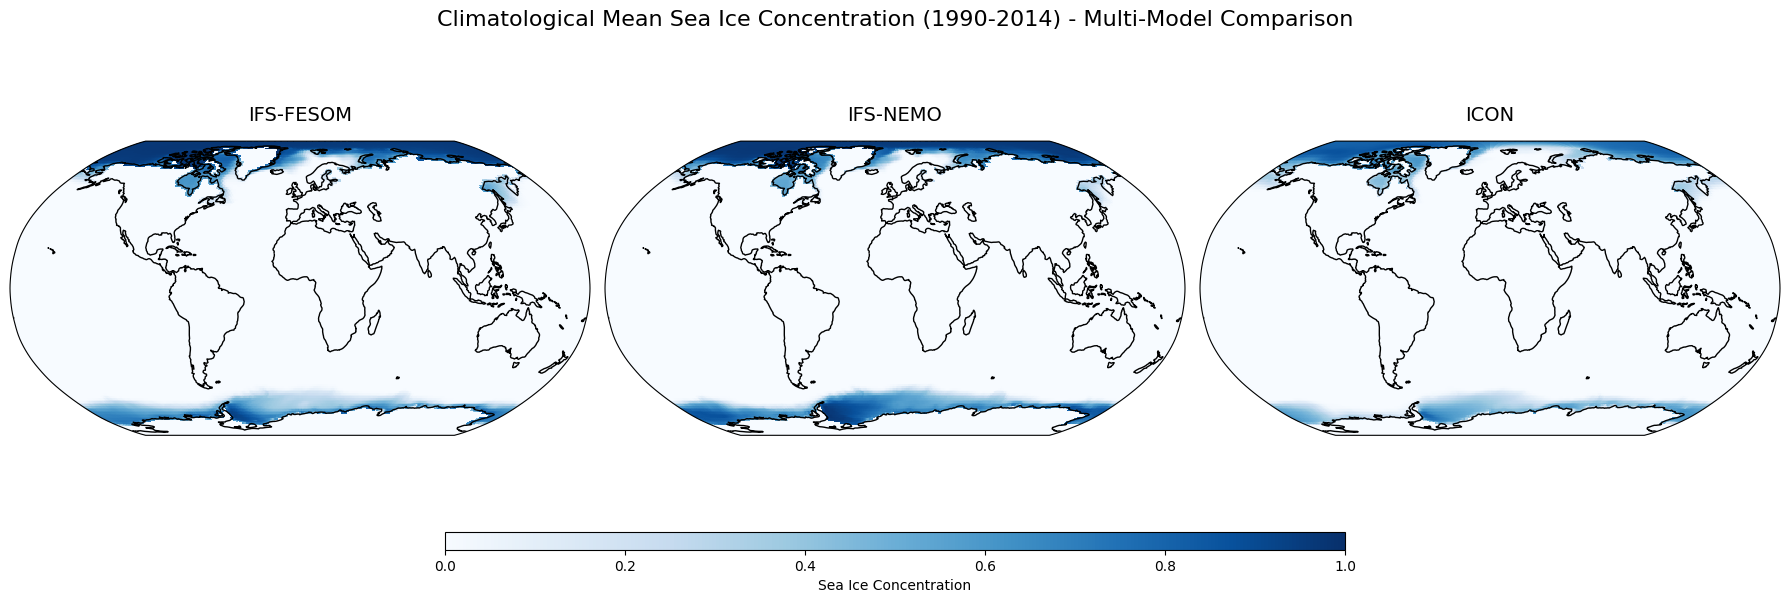

In [3]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# List of data and model names
data_list = [siconc_fesom_clim, siconc_nemo_clim, siconc_icon_clim]
model_names = ["IFS-FESOM", "IFS-NEMO", "ICON"]

# Create figure and axes (1 row x 3 columns)
fig, axes = plt.subplots(1, 3, figsize=(18,6),
                         subplot_kw={'projection': ccrs.Robinson()})

# Plot each model
for i, (data, name) in enumerate(zip(data_list, model_names)):
    ax = axes[i]
    im = data.plot(ax=ax, transform=ccrs.PlateCarree(),
                   cmap="Blues", vmin=0, vmax=1, add_colorbar=False)
    ax.coastlines()
    ax.add_feature(cfeature.LAND, facecolor="lightgray")
    ax.set_title(name, fontsize=14, pad=15)

# Add a single colorbar for all
cbar_ax = fig.add_axes([0.25, 0.05, 0.5, 0.03])  # [left, bottom, width, height]
cbar = fig.colorbar(im, cax=cbar_ax, orientation='horizontal')
cbar.set_label("Sea Ice Concentration")

plt.suptitle("Climatological Mean Sea Ice Concentration (1990-2014) - Multi-Model Comparison", fontsize=16, y=0.95)
plt.tight_layout(rect=[0,0.1,1,0.93])  # leave space for colorbar and suptitle
plt.show()

/tmp/ipykernel_529043/3123186362.py:36: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0,0.1,1,0.93])


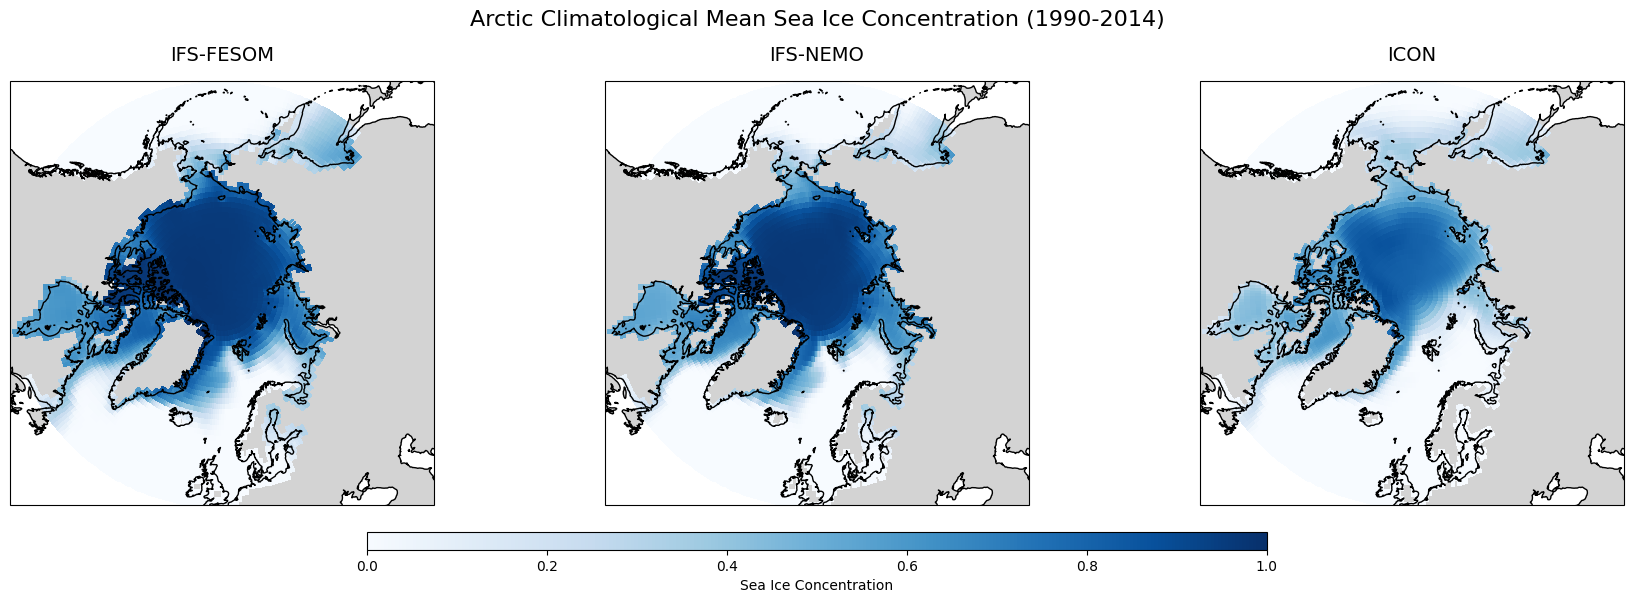

In [12]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Define Arctic latitude mask (>= 50°N)
arctic_lat_min = 50

data_list = [siconc_fesom_clim, siconc_nemo_clim, siconc_icon_clim]
model_names = ["IFS-FESOM", "IFS-NEMO", "ICON"]

# Create figure and axes (1 row x 3 columns)
fig, axes = plt.subplots(1, 3, figsize=(18,6),
                         subplot_kw={'projection': ccrs.NorthPolarStereo()})

for i, (data, name) in enumerate(zip(data_list, model_names)):
    ax = axes[i]
    
    # Select only Arctic latitudes
    arctic_data = data.where(data.lat >= arctic_lat_min, drop=True)
    
    # Plot
    im = arctic_data.plot(ax=ax, transform=ccrs.PlateCarree(),
                          cmap="Blues", vmin=0, vmax=1, add_colorbar=False)
    
    ax.coastlines(resolution='50m')
    ax.add_feature(cfeature.LAND, facecolor="lightgray")
    ax.set_title(name, fontsize=14, pad=15)
    ax.set_extent([-180, 180, arctic_lat_min, 90], crs=ccrs.PlateCarree())  # zoom to Arctic

# Single colorbar
cbar_ax = fig.add_axes([0.25, 0.05, 0.5, 0.03])  # [left, bottom, width, height]
cbar = fig.colorbar(im, cax=cbar_ax, orientation='horizontal')
cbar.set_label("Sea Ice Concentration")

plt.suptitle("Arctic Climatological Mean Sea Ice Concentration (1990-2014)", fontsize=16, y=0.95)
plt.tight_layout(rect=[0,0.1,1,0.93])
plt.show()

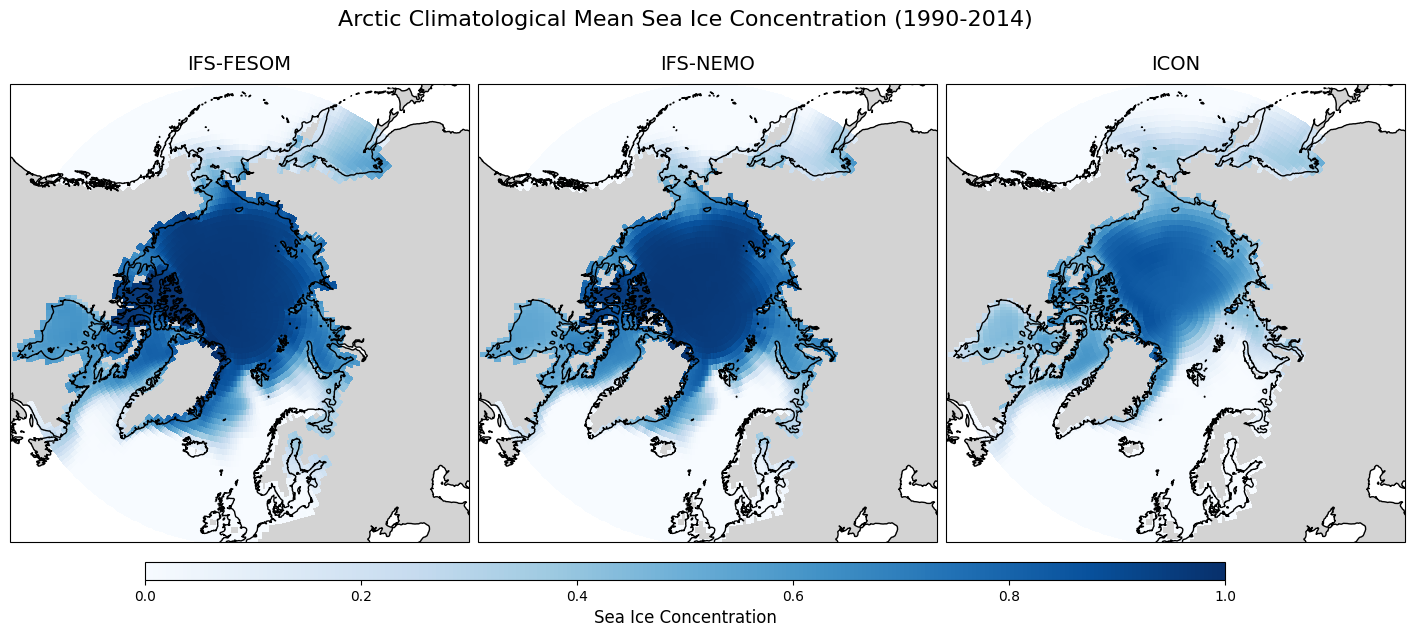

In [9]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Arctic latitude threshold
arctic_lat_min = 50

data_list = [siconc_fesom_clim, siconc_nemo_clim, siconc_icon_clim]
model_names = ["IFS-FESOM", "IFS-NEMO", "ICON"]

# Create figure and axes (1 row x 3 columns)
fig, axes = plt.subplots(1, 3, figsize=(18,6),
                         subplot_kw={'projection': ccrs.NorthPolarStereo()})

# Adjust spacing
plt.subplots_adjust(wspace=0.02, hspace=0.05)  # reduce horizontal gap

for i, (data, name) in enumerate(zip(data_list, model_names)):
    ax = axes[i]
    
    # Select Arctic latitudes
    arctic_data = data.where(data.lat >= arctic_lat_min, drop=True)
    
    # Plot with a distinctive colormap
    im = arctic_data.plot(ax=ax, transform=ccrs.PlateCarree(),
                          cmap="Blues", vmin=0, vmax=1, add_colorbar=False)
    
    ax.coastlines(resolution='50m')
    ax.add_feature(cfeature.LAND, facecolor="lightgray")
    ax.set_title(name, fontsize=14, pad=10)
    
    # Set extent to focus on Arctic
    ax.set_extent([-180, 180, arctic_lat_min, 90], crs=ccrs.PlateCarree())

# Single colorbar below
cbar_ax = fig.add_axes([0.2, 0.05, 0.6, 0.03])  # wider and centered
cbar = fig.colorbar(im, cax=cbar_ax, orientation='horizontal')
cbar.set_label("Sea Ice Concentration", fontsize=12)

plt.suptitle("Arctic Climatological Mean Sea Ice Concentration (1990-2014)", fontsize=16, y=1.0)
plt.show()

In [5]:
# Load the combined siconc files

import xarray as xr

folder = f"{EVA_DIR}/"

# Load combined NetCDFs
siconc_icon = xr.open_dataset(folder + "siconc_ICON_1990-2014.nc")["siconc"]
siconc_fesom = xr.open_dataset(folder + "siconc_FESOM_1990-2014.nc")["siconc"]
siconc_nemo = xr.open_dataset(folder + "siconc_NEMO_1990-2014.nc")["siconc"]

print(siconc_icon)

<xarray.DataArray 'siconc' (time: 300, lat: 180, lon: 360)>
[19440000 values with dtype=float64]
Coordinates:
  * time     (time) datetime64[ns] 1990-01-01 1990-02-01 ... 2014-12-01
  * lat      (lat) float64 -89.5 -88.5 -87.5 -86.5 -85.5 ... 86.5 87.5 88.5 89.5
  * lon      (lon) float64 0.0 1.0 2.0 3.0 4.0 ... 355.0 356.0 357.0 358.0 359.0
Attributes: (12/35)
    GRIB_paramId:                    263001
    model:                           ICON
    long_name:                       Sea ice area fraction
    shortName:                       siconc
    GRIB_stepUnits:                  1
    type:                            fc
    ...                              ...
    experiment:                      hist
    paramId:                         262001
    GRIB_units:                      Fraction
    stream:                          clte
    GRIB_dataType:                   fc
    description:                     Combined monthly sea ice concentration 1...


In [6]:
import xarray as xr

# Arctic latitude threshold
arctic_lat_min = 50

# Function to compute seasonal mean for a DataArray
def seasonal_mean(data, season):
    time = data['time']  # Access the coordinate
    if season == "DJF":
        # December + Jan, Feb
        dec = data.sel(time=time.dt.month==12)
        jan_feb = data.sel(time=time.dt.month.isin([1,2]))
        combined = xr.concat([dec, jan_feb], dim="time")
        seasonal = combined.groupby("time.year").mean("time")
        return seasonal.mean("year")
    elif season == "JJA":
        summer = data.sel(time=time.dt.month.isin([6,7,8]))
        seasonal = summer.groupby("time.year").mean("time")
        return seasonal.mean("year")
    else:
        raise ValueError("Season must be 'DJF' or 'JJA'")

# Compute Arctic seasonal means for all three models
siconc_fesom_arctic = siconc_fesom.where(siconc_fesom.lat>=arctic_lat_min, drop=True)
siconc_nemo_arctic = siconc_nemo.where(siconc_nemo.lat>=arctic_lat_min, drop=True)
siconc_icon_arctic = siconc_icon.where(siconc_icon.lat>=arctic_lat_min, drop=True)

# Seasonal means
siconc_seasonal = {}
for season in ["DJF", "JJA"]:
    siconc_seasonal[season] = [
        seasonal_mean(siconc_fesom_arctic, season),
        seasonal_mean(siconc_nemo_arctic, season),
        seasonal_mean(siconc_icon_arctic, season)
    ]

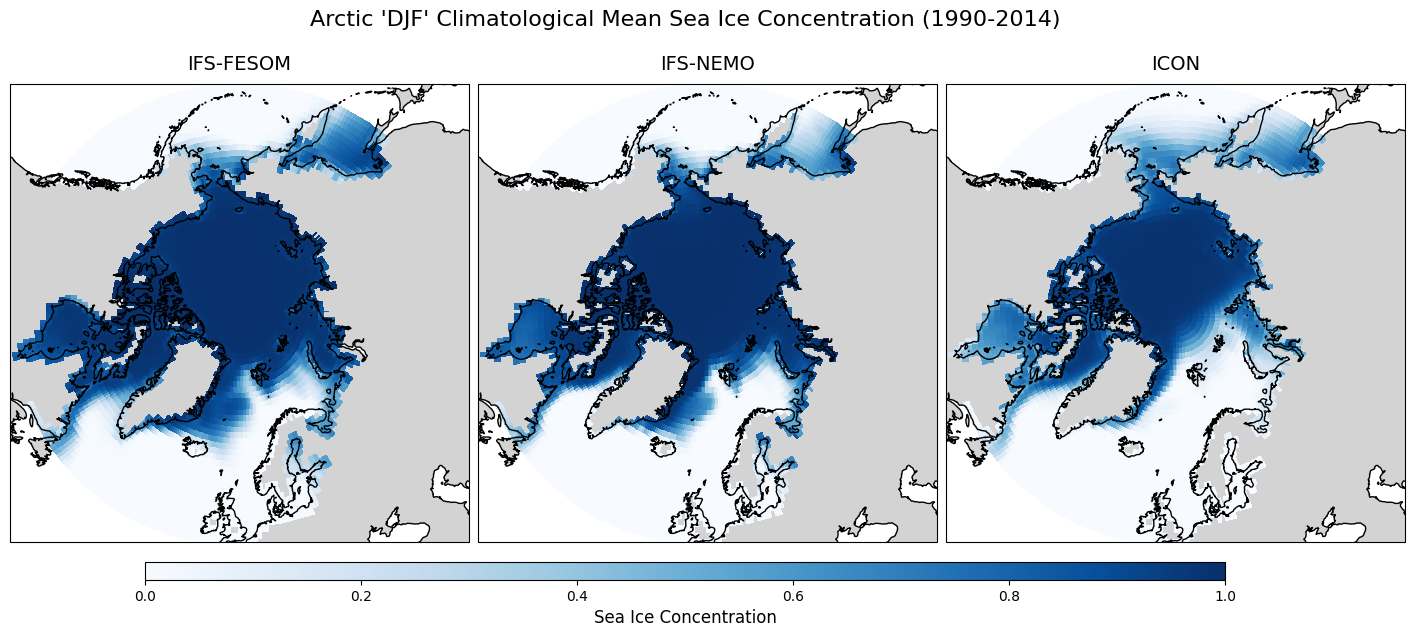

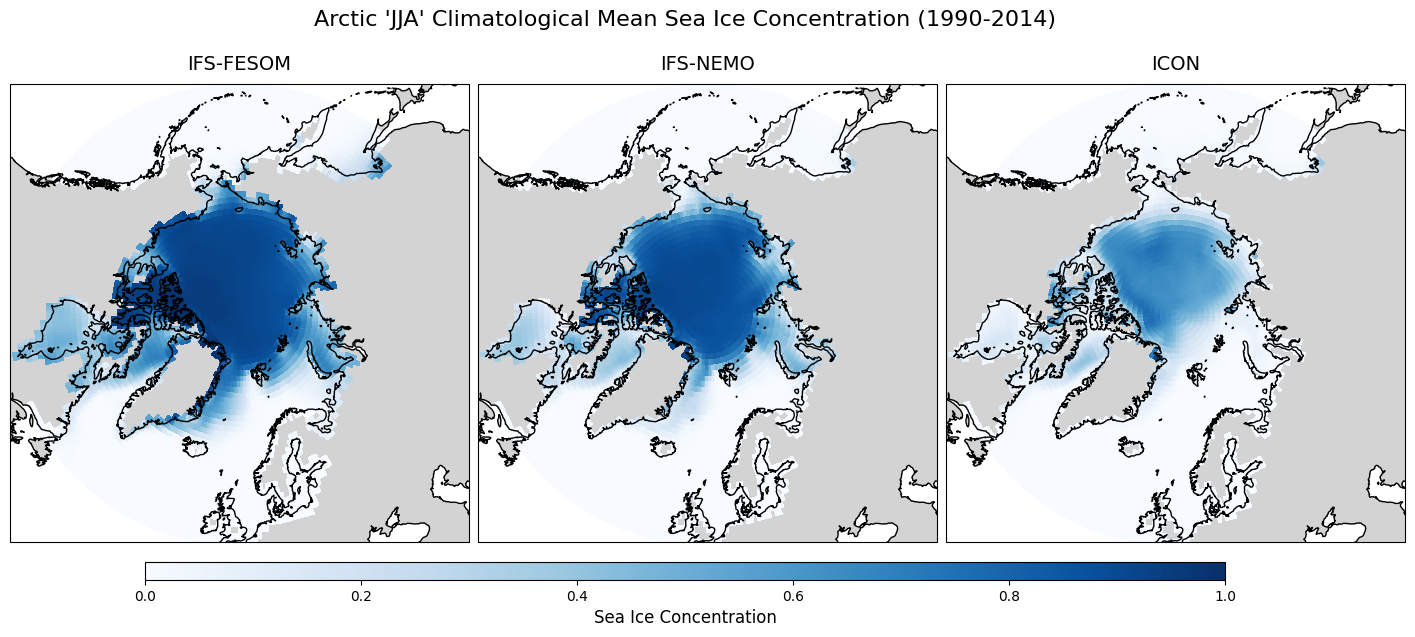

In [8]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

model_names = ["IFS-FESOM", "IFS-NEMO", "ICON"]

for season in ["DJF", "JJA"]:
    fig, axes = plt.subplots(1, 3, figsize=(18,6),
                             subplot_kw={'projection': ccrs.NorthPolarStereo()})
    plt.subplots_adjust(wspace=0.02, hspace=0.05)
    
    for i, (data, name) in enumerate(zip(siconc_seasonal[season], model_names)):
        ax = axes[i]
        im = data.plot(ax=ax, transform=ccrs.PlateCarree(),
                       cmap="Blues", vmin=0, vmax=1, add_colorbar=False)
        ax.coastlines(resolution='50m')
        ax.add_feature(cfeature.LAND, facecolor="lightgray")
        ax.set_title(name, fontsize=14, pad=10)
        ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())

    # Single colorbar
    cbar_ax = fig.add_axes([0.2, 0.05, 0.6, 0.03])
    cbar = fig.colorbar(im, cax=cbar_ax, orientation='horizontal')
    cbar.set_label("Sea Ice Concentration", fontsize=12)
    
    plt.suptitle(f"Arctic '{season}' Climatological Mean Sea Ice Concentration (1990-2014)",
                 fontsize=16, y=1.0)
    plt.show()

## March and September: Arctic

In [14]:
# -------------------------------
# Cell 1: Extract March and September climatology (Arctic)
# -------------------------------
import xarray as xr

# Models
folder = f"{EVA_DIR}/"
model_files = {
    "IFS-FESOM": folder + "siconc_FESOM_1990-2014.nc",
    "IFS-NEMO": folder + "siconc_NEMO_1990-2014.nc",
    "ICON": folder + "siconc_ICON_1990-2014.nc"
}

# Load datasets
siconc_data = {name: xr.open_dataset(path)["siconc"] for name, path in model_files.items()}

# Extract March (3) and September (9) means across years
siconc_monthly = {}
for month, mnum in [("March", 3), ("September", 9)]:
    siconc_monthly[month] = [
        da.sel(time=da['time.month'] == mnum).mean(dim='time') for da in siconc_data.values()
    ]

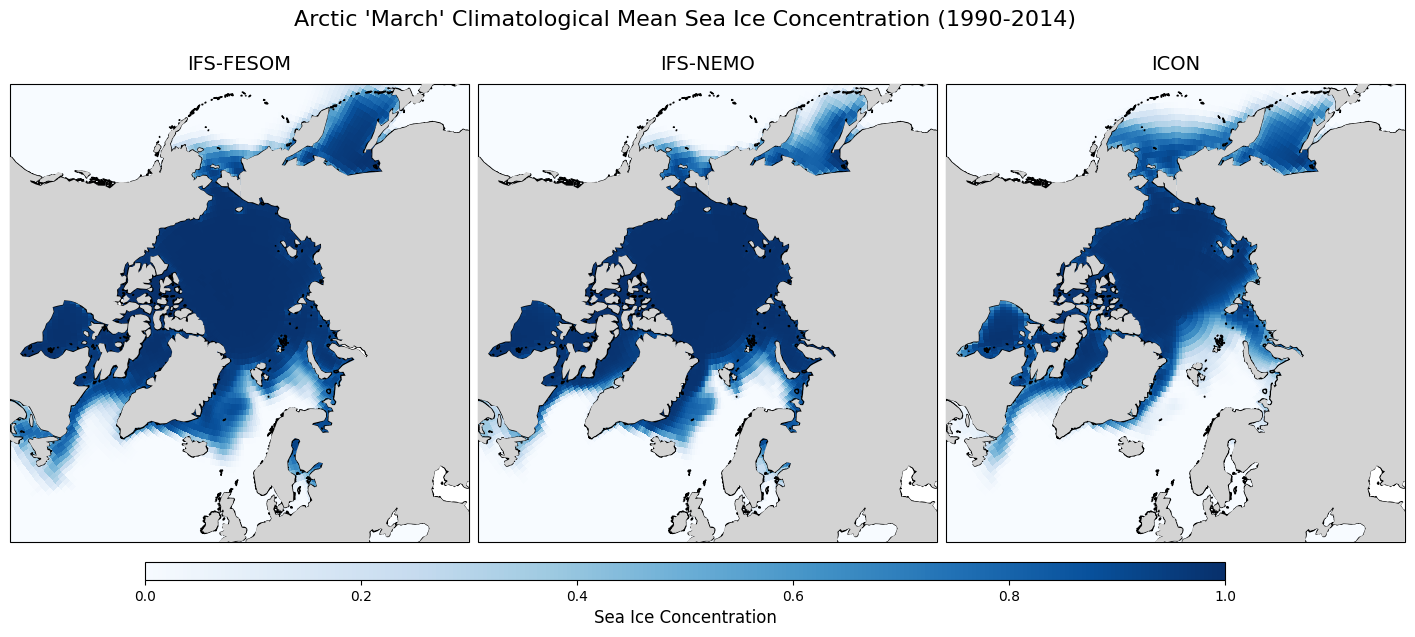

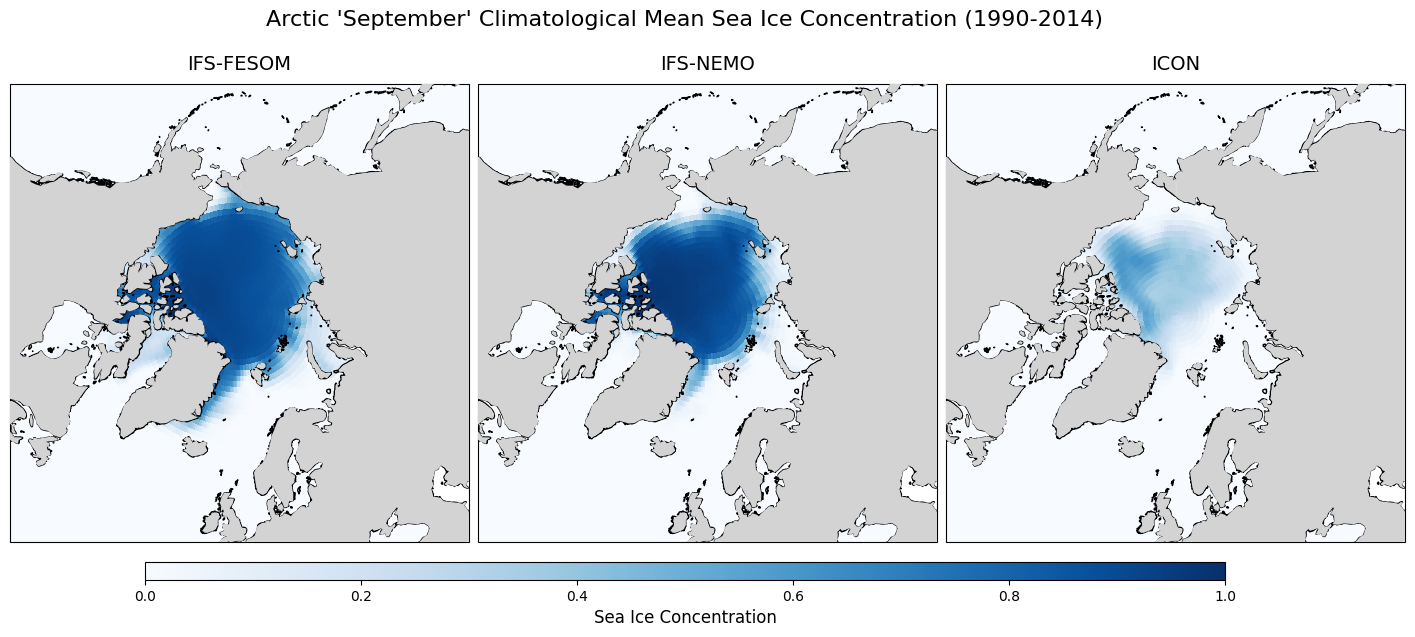

In [19]:
# -------------------------------
# Cell 2: Arctic Sea Ice Concentration Maps (March & September)
# -------------------------------
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

model_names = ["IFS-FESOM", "IFS-NEMO", "ICON"]

for month in ["March", "September"]:
    fig, axes = plt.subplots(1, 3, figsize=(18,6),
                             subplot_kw={'projection': ccrs.NorthPolarStereo()})
    plt.subplots_adjust(wspace=0.02, hspace=0.05)
    
    for i, (data, name) in enumerate(zip(siconc_monthly[month], model_names)):
        ax = axes[i]
        im = data.plot(ax=ax, transform=ccrs.PlateCarree(),
                       cmap="Blues", vmin=0, vmax=1, add_colorbar=False)
        
        # Coastlines first
        ax.coastlines(resolution='50m')
        # Land last (on top of ice)
        ax.add_feature(cfeature.LAND, facecolor="lightgray", zorder=10)
        
        ax.set_title(name, fontsize=14, pad=10)
        ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())

    # Single horizontal colorbar
    cbar_ax = fig.add_axes([0.2, 0.05, 0.6, 0.03])
    cbar = fig.colorbar(im, cax=cbar_ax, orientation='horizontal')
    cbar.set_label("Sea Ice Concentration", fontsize=12)
    
    plt.suptitle(f"Arctic '{month}' Climatological Mean Sea Ice Concentration (1990-2014)",
                 fontsize=16, y=1.0)
    plt.show()

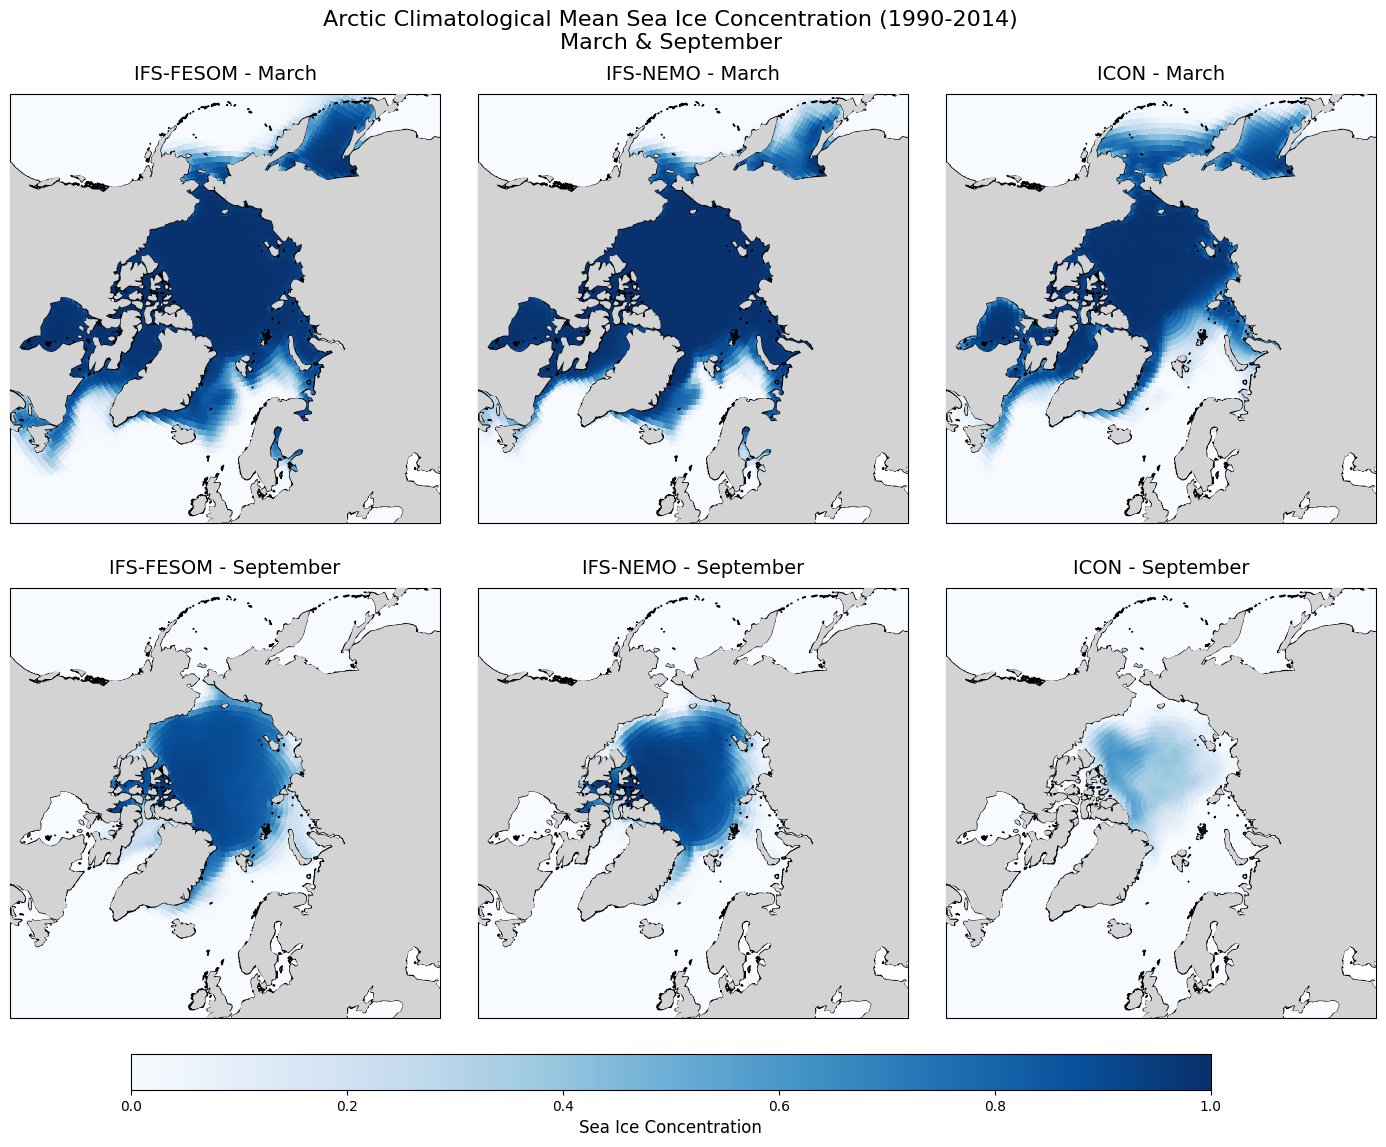

In [28]:
# -------------------------------
# Arctic Sea Ice Concentration Maps (March & September) in one figure (2x3)
# -------------------------------
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

model_names = ["IFS-FESOM", "IFS-NEMO", "ICON"]
months = ["March", "September"]

fig, axes = plt.subplots(2, 3, figsize=(18, 12),
                         subplot_kw={'projection': ccrs.NorthPolarStereo()})
# Increase hspace to avoid overlap between rows
plt.subplots_adjust(wspace=0.02, hspace=0.15)

for row, month in enumerate(months):
    for col, (data, name) in enumerate(zip(siconc_monthly[month], model_names)):
        ax = axes[row, col]
        
        # Plot sea ice concentration
        im = data.plot(ax=ax, transform=ccrs.PlateCarree(),
                       cmap="Blues", vmin=0, vmax=1, add_colorbar=False)
        
        # Coastlines first
        ax.coastlines(resolution='50m')
        # Land on top
        ax.add_feature(cfeature.LAND, facecolor="lightgray", zorder=10)
        
        ax.set_title(f"{name} - {month}", fontsize=14, pad=10)
        ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())

# Single horizontal colorbar
cbar_ax = fig.add_axes([0.2, 0.05, 0.6, 0.03])
cbar = fig.colorbar(im, cax=cbar_ax, orientation='horizontal')
cbar.set_label("Sea Ice Concentration", fontsize=12)

plt.suptitle("Arctic Climatological Mean Sea Ice Concentration (1990-2014)\nMarch & September",
             fontsize=16, y=0.95)
plt.show()

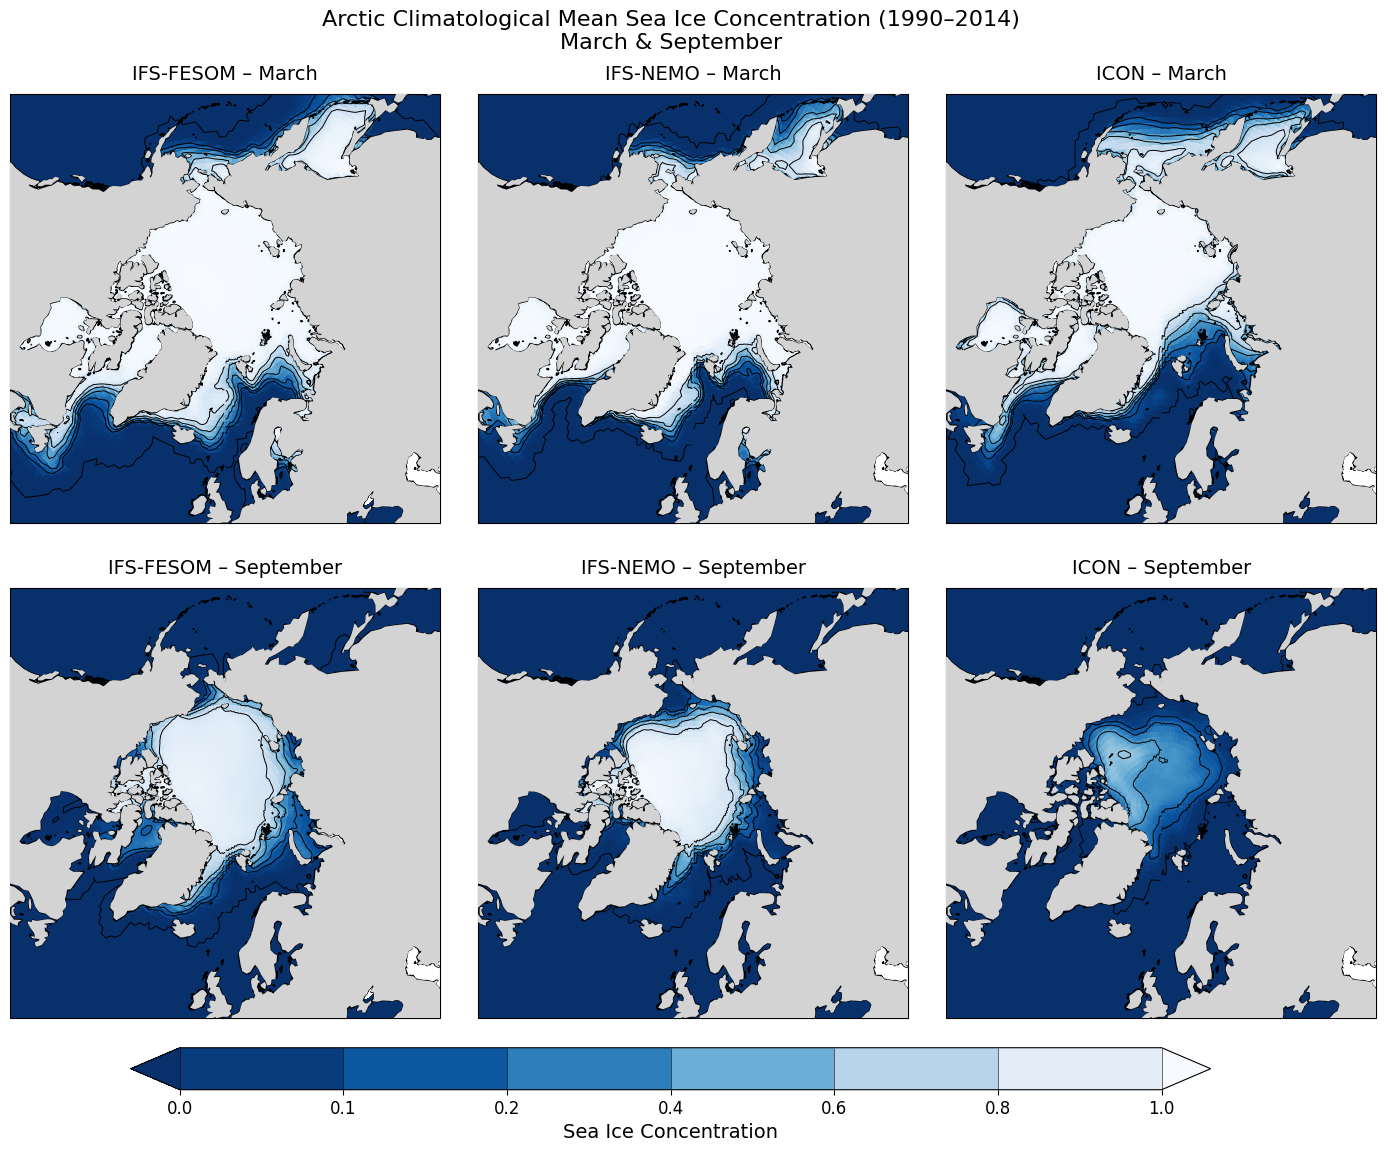

In [16]:
# -------------------------------
# Arctic Sea Ice Concentration Maps (March & September) in one figure (2x3)
# -------------------------------
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

model_names = ["IFS-FESOM", "IFS-NEMO", "ICON"]
months = ["March", "September"]

# Colorbar levels (fraction)
levels = [0.0, 0.1, 0.2, 0.4, 0.6, 0.8, 1.0]

fig, axes = plt.subplots(
    2, 3, figsize=(18, 12),
    subplot_kw={"projection": ccrs.NorthPolarStereo()}
)

# Increase hspace to avoid overlap between rows
plt.subplots_adjust(wspace=0.02, hspace=0.15)

for row, month in enumerate(months):
    for col, (data, name) in enumerate(zip(siconc_monthly[month], model_names)):
        ax = axes[row, col]

        # Filled field
        im = data.plot(
            ax=ax,
            transform=ccrs.PlateCarree(),
            cmap="Blues_r",
            vmin=0,
            vmax=1,
            add_colorbar=False
        )

        # Optional: contour lines at selected levels (no labels)
        ax.contour(
            data.lon, data.lat, data,
            levels=levels,
            colors="k",
            linewidths=0.7,
            transform=ccrs.PlateCarree()
        )

        # Coastlines first
        ax.coastlines(resolution="50m")
        # Land overlay last
        ax.add_feature(cfeature.LAND, facecolor="lightgray", zorder=10)

        ax.set_title(f"{name} – {month}", fontsize=14, pad=10)
        ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())

# Shared horizontal colorbar with internal boundary lines at tick levels
cbar_ax = fig.add_axes([0.2, 0.05, 0.6, 0.035])
cbar = fig.colorbar(
    im,
    cax=cbar_ax,
    orientation="horizontal",
    extend="both",
    ticks=levels,
    boundaries=levels,
    drawedges=True
)

cbar.set_label("Sea Ice Concentration", fontsize=14)
cbar.ax.tick_params(labelsize=12)

# Make internal colorbar edges visible
cbar.outline.set_linewidth(1.0)
for spine in cbar.ax.spines.values():
    spine.set_linewidth(0.8)

plt.suptitle(
    "Arctic Climatological Mean Sea Ice Concentration (1990–2014)\nMarch & September",
    fontsize=16, y=0.95
)

plt.show()

# Sea Ice thickness

In [2]:
# Load the combined siconc files

import xarray as xr

folder = f"{EVA_DIR}/"

# Load combined NetCDFs
sithick_icon = xr.open_dataset(folder + "sithick_ICON_1990-2014.nc")["sithick"]
sithick_fesom = xr.open_dataset(folder + "sithick_FESOM_1990-2014.nc")["sithick"]
sithick_nemo = xr.open_dataset(folder + "sithick_NEMO_1990-2014.nc")["sithick"]

print(sithick_icon)

<xarray.DataArray 'sithick' (time: 300, lat: 180, lon: 360)>
[19440000 values with dtype=float64]
Coordinates:
  * time     (time) datetime64[ns] 1990-01-01 1990-02-01 ... 2014-12-01
  * lat      (lat) float64 -89.5 -88.5 -87.5 -86.5 -85.5 ... 86.5 87.5 88.5 89.5
  * lon      (lon) float64 0.0 1.0 2.0 3.0 4.0 ... 355.0 356.0 357.0 358.0 359.0
Attributes: (12/35)
    GRIB_paramId:                    263000
    model:                           ICON
    long_name:                       Sea ice thickness
    shortName:                       sithick
    GRIB_stepUnits:                  1
    type:                            fc
    ...                              ...
    experiment:                      hist
    paramId:                         262000
    GRIB_units:                      m
    stream:                          clte
    GRIB_dataType:                   fc
    description:                     Combined monthly sea ice thickness 1990-...


In [3]:
# Compute climatological mean

sithick_icon_clim = sithick_icon.mean(dim="time")
sithick_fesom_clim = sithick_fesom.mean(dim="time")
sithick_nemo_clim = sithick_nemo.mean(dim="time")

## Arctic only

In [4]:
# -------------------------------
# Cell 1: Extract March and September climatology (Arctic sea ice thickness)
# -------------------------------
import xarray as xr

# Models and data paths
folder = f"{EVA_DIR}/"
model_files = {
    "IFS-FESOM": folder + "sithick_FESOM_1990-2014.nc",
    "IFS-NEMO":  folder + "sithick_NEMO_1990-2014.nc",
    "ICON":      folder + "sithick_ICON_1990-2014.nc"
}

# Load sea ice thickness datasets
sithick_data = {
    name: xr.open_dataset(path)["sithick"]
    for name, path in model_files.items()
}

# Extract March (3) and September (9) climatological means across 1990–2014
sithick_monthly = {}
for month, mnum in [("March", 3), ("September", 9)]:
    sithick_monthly[month] = [
        da.sel(time=da["time.month"] == mnum).mean(dim="time")
        for da in sithick_data.values()
    ]

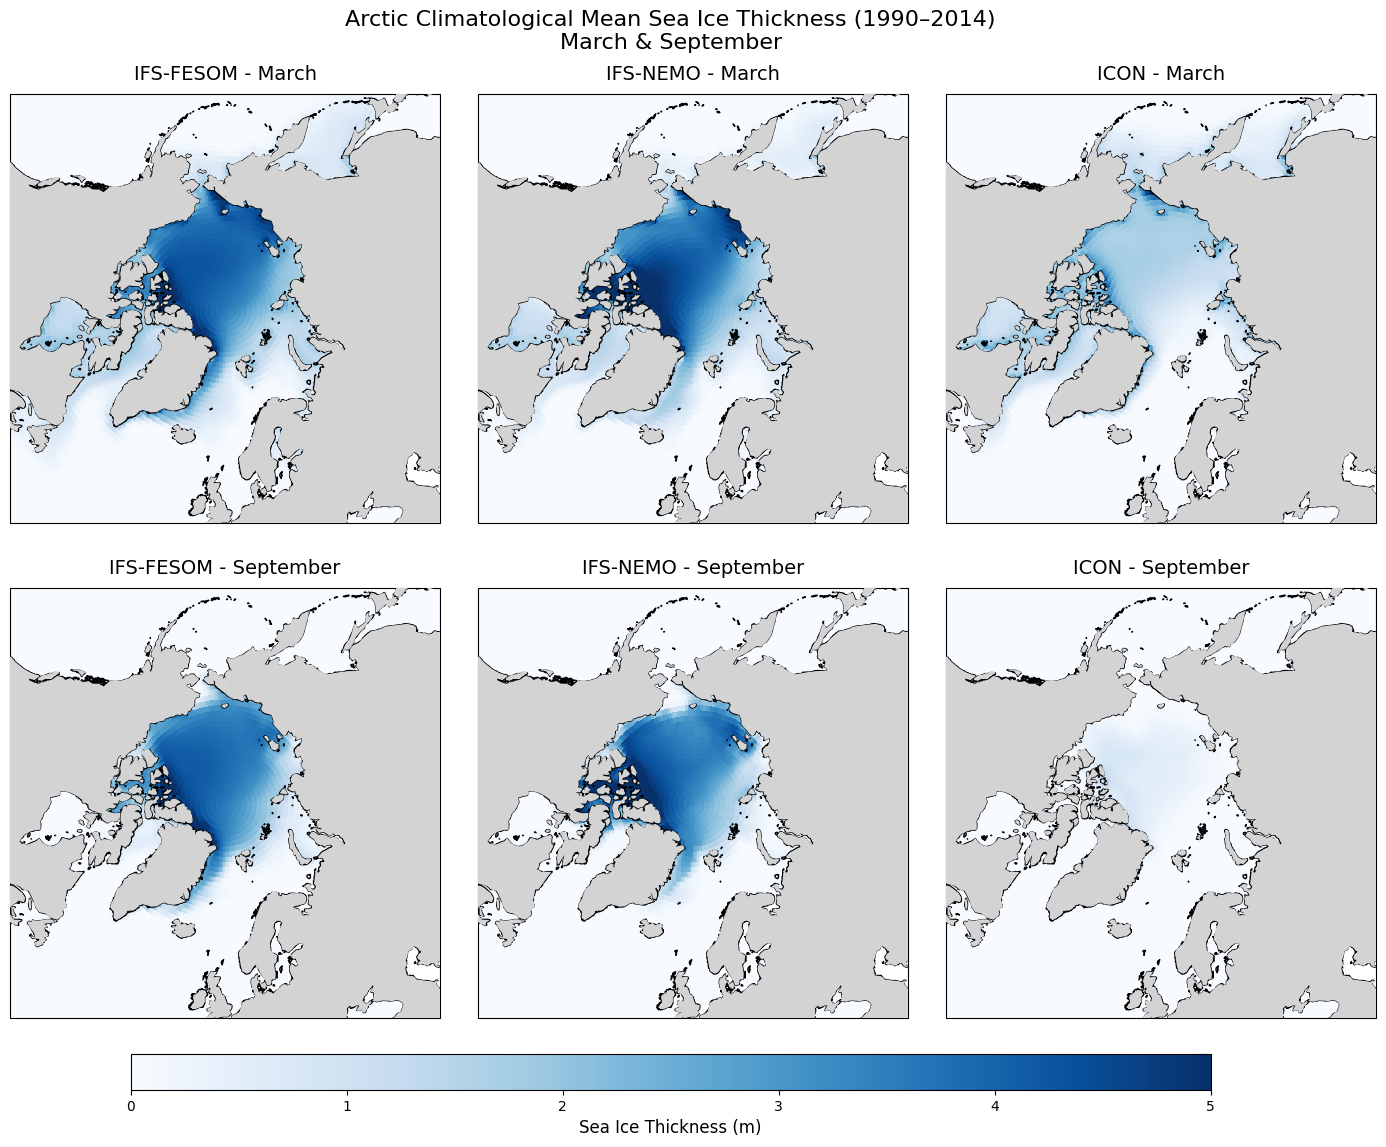

In [6]:
# -------------------------------
# Cell 2: Arctic Sea Ice Thickness Maps (March & September)
# -------------------------------
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

model_names = ["IFS-FESOM", "IFS-NEMO", "ICON"]
months = ["March", "September"]

fig, axes = plt.subplots(
    2, 3, figsize=(18, 12),
    subplot_kw={'projection': ccrs.NorthPolarStereo()}
)

# Adjust spacing to avoid overlap
plt.subplots_adjust(wspace=0.02, hspace=0.15)

for row, month in enumerate(months):
    for col, (data, name) in enumerate(zip(sithick_monthly[month], model_names)):
        ax = axes[row, col]

        # Plot sea ice thickness
        im = data.plot(
            ax=ax,
            transform=ccrs.PlateCarree(),
            cmap="Blues",     # Better perceptual map for thickness
            vmin=0,
            vmax=5,             # Typical Arctic thickness range (m)
            add_colorbar=False
        )

        # Coastlines first
        ax.coastlines(resolution="50m")
        # Land on top (important for polar plots)
        ax.add_feature(cfeature.LAND, facecolor="lightgray", zorder=10)

        ax.set_title(f"{name} - {month}", fontsize=14, pad=10)
        ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())

# Single horizontal colorbar
cbar_ax = fig.add_axes([0.2, 0.05, 0.6, 0.03])
cbar = fig.colorbar(im, cax=cbar_ax, orientation="horizontal")
cbar.set_label("Sea Ice Thickness (m)", fontsize=12)

plt.suptitle(
    "Arctic Climatological Mean Sea Ice Thickness (1990–2014)\nMarch & September",
    fontsize=16, y=0.95
)

plt.show()

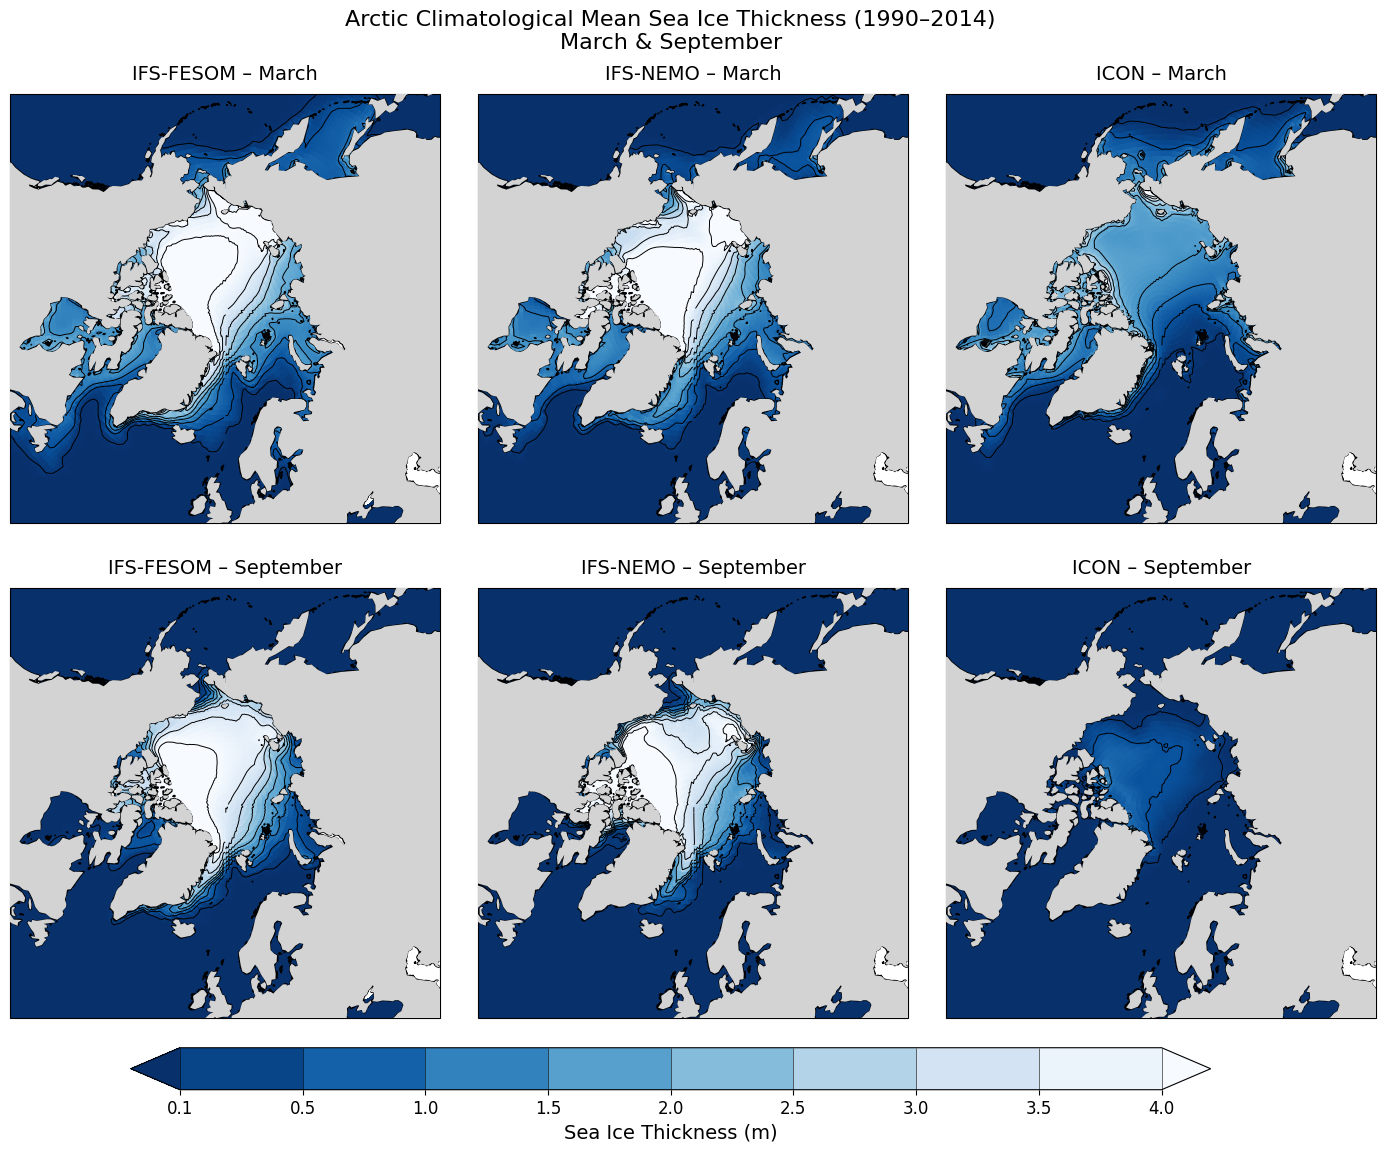

In [10]:
# -------------------------------
# Cell 2: Arctic Sea Ice Thickness Maps (March & September)
# -------------------------------
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

model_names = ["IFS-FESOM", "IFS-NEMO", "ICON"]
months = ["March", "September"]

# Contour / colorbar levels (meters)
levels = [0.1, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0]

fig, axes = plt.subplots(
    2, 3, figsize=(18, 12),
    subplot_kw={"projection": ccrs.NorthPolarStereo()}
)

plt.subplots_adjust(wspace=0.02, hspace=0.15)

for row, month in enumerate(months):
    for col, (data, name) in enumerate(zip(sithick_monthly[month], model_names)):
        ax = axes[row, col]

        # Filled field
        im = data.plot(
            ax=ax,
            transform=ccrs.PlateCarree(),
            cmap="Blues_r",
            vmin=0,
            vmax=4,
            add_colorbar=False
        )

        # Contour lines only (no labels)
        ax.contour(
            data.lon, data.lat, data,
            levels=levels,
            colors="k",
            linewidths=0.7,
            transform=ccrs.PlateCarree()
        )

        # Coastlines first
        ax.coastlines(resolution="50m")

        # Land overlay LAST
        ax.add_feature(cfeature.LAND, facecolor="lightgray", zorder=10)

        ax.set_title(f"{name} – {month}", fontsize=14, pad=10)
        ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())

# Shared horizontal colorbar with internal boundary lines
cbar_ax = fig.add_axes([0.2, 0.05, 0.6, 0.035])
cbar = fig.colorbar(
    im,
    cax=cbar_ax,
    orientation="horizontal",
    extend="both",
    ticks=levels,
    boundaries=levels,
    drawedges=True
)

cbar.set_label("Sea Ice Thickness (m)", fontsize=14)
cbar.ax.tick_params(labelsize=12)

# Make the internal boundary lines visible but subtle
cbar.outline.set_linewidth(1.0)
for spine in cbar.ax.spines.values():
    spine.set_linewidth(0.8)

plt.suptitle(
    "Arctic Climatological Mean Sea Ice Thickness (1990–2014)\nMarch & September",
    fontsize=16, y=0.95
)

plt.show()

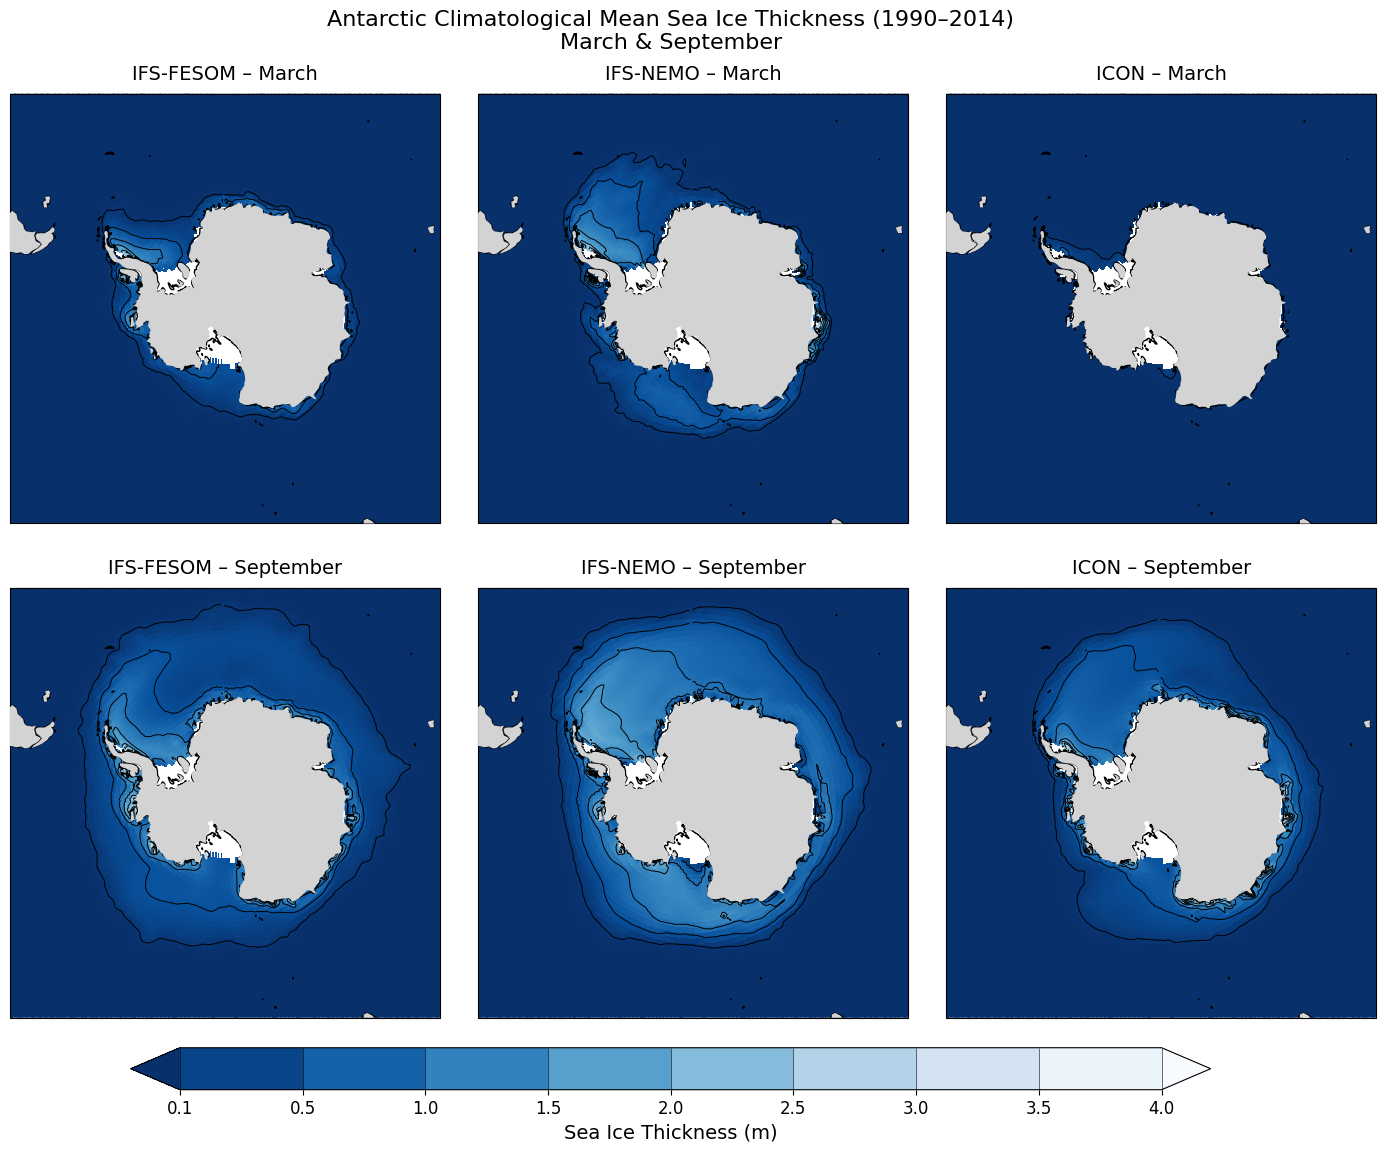

In [13]:
# -------------------------------
# Cell 2: Antarctic Sea Ice Thickness Maps (March & September)
# -------------------------------
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

model_names = ["IFS-FESOM", "IFS-NEMO", "ICON"]
months = ["March", "September"]

# Contour / colorbar levels (meters)
levels = [0.1, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0]

fig, axes = plt.subplots(
    2, 3, figsize=(18, 12),
    subplot_kw={"projection": ccrs.SouthPolarStereo()}
)

plt.subplots_adjust(wspace=0.02, hspace=0.15)

for row, month in enumerate(months):
    for col, (data, name) in enumerate(zip(sithick_monthly[month], model_names)):
        ax = axes[row, col]

        # Filled field
        im = data.plot(
            ax=ax,
            transform=ccrs.PlateCarree(),
            cmap="Blues_r",
            vmin=0,
            vmax=4,
            add_colorbar=False
        )

        # Contour lines only (no labels)
        ax.contour(
            data.lon,
            data.lat,
            data,
            levels=levels,
            colors="k",
            linewidths=0.7,
            transform=ccrs.PlateCarree()
        )

        # Coastlines first
        ax.coastlines(resolution="50m")

        # Land overlay LAST
        ax.add_feature(cfeature.LAND, facecolor="lightgray", zorder=10)

        ax.set_title(f"{name} – {month}", fontsize=14, pad=10)
        ax.set_extent([-180, 180, -90, -50], crs=ccrs.PlateCarree())

# Shared horizontal colorbar with internal boundary lines
cbar_ax = fig.add_axes([0.2, 0.05, 0.6, 0.035])
cbar = fig.colorbar(
    im,
    cax=cbar_ax,
    orientation="horizontal",
    extend="both",
    ticks=levels,
    boundaries=levels,
    drawedges=True
)

cbar.set_label("Sea Ice Thickness (m)", fontsize=14)
cbar.ax.tick_params(labelsize=12)

# Make the internal boundary lines visible but subtle
cbar.outline.set_linewidth(1.0)
for spine in cbar.ax.spines.values():
    spine.set_linewidth(0.8)

plt.suptitle(
    "Antarctic Climatological Mean Sea Ice Thickness (1990–2014)\nMarch & September",
    fontsize=16, y=0.95
)

plt.show()

# Error

In [2]:
import xarray as xr

path = f"{LRA_ROOT}/climatedt-o25.1/IFS-FESOM/historical-1990/r100/monthly/thetao_o00i_r100_monthly_1990.nc"

ds = xr.open_dataset(path)

print(ds)

<xarray.Dataset>
Dimensions:    (time: 12, level: 69, lat: 180, lon: 360)
Coordinates:
  * level      (level) float64 2.5 7.5 12.5 ... 5.525e+03 5.825e+03 6.175e+03
    idx_level  (level) int64 ...
  * time       (time) datetime64[ns] 1990-01-01 1990-02-01 ... 1990-12-01
  * lat        (lat) float64 -89.5 -88.5 -87.5 -86.5 ... 86.5 87.5 88.5 89.5
  * lon        (lon) float64 0.0 1.0 2.0 3.0 4.0 ... 356.0 357.0 358.0 359.0
Data variables:
    thetao     (time, level, lat, lon) float64 ...


/tmp/ipykernel_3755780/1588745495.py:88: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


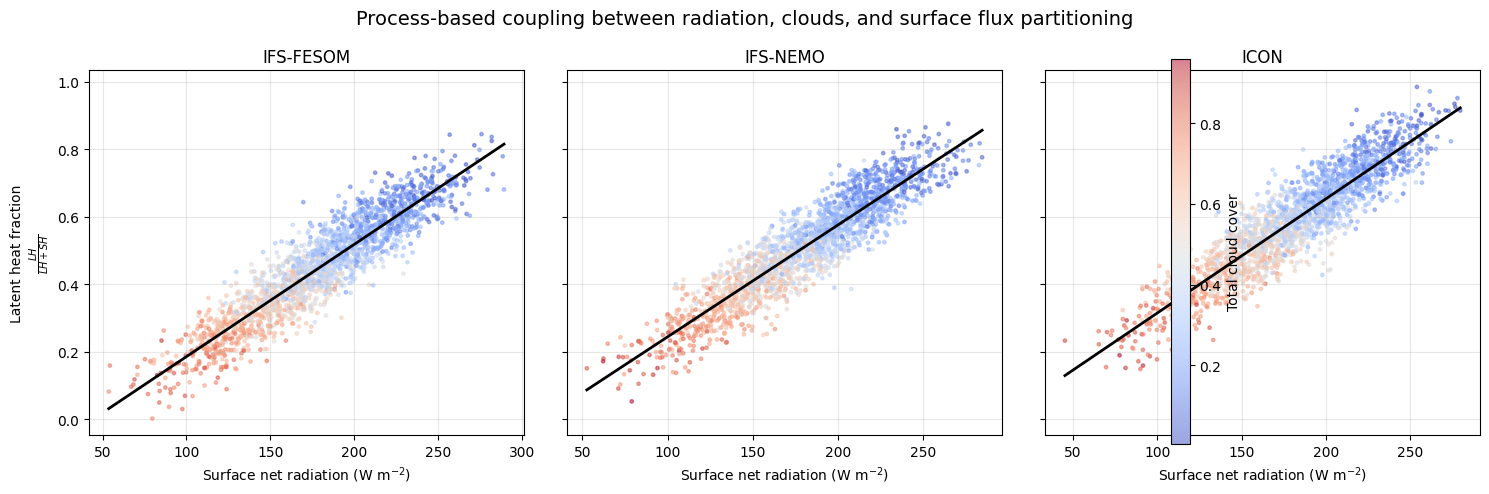

In [2]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# --------------------------------------------------------
# Helper function to generate synthetic, physically
# consistent data for one model
# --------------------------------------------------------
def generate_model_data(n=2000, model_bias=0.0):
    """
    n          : number of points
    model_bias : controls slope / behaviour differences
    """

    # Total cloud cover [0, 1]
    tcc = np.clip(np.random.beta(2, 3, n), 0, 1)

    # Net surface radiation (W m-2)
    # Clouds reduce radiation
    net_rad = (
        250 * (1 - 0.7 * tcc)      # cloud modulation
        + np.random.normal(0, 20, n)
    )

    # Latent heat fraction (dimensionless)
    # Higher radiation -> higher latent fraction
    # Add model-specific bias
    lhf = (
        0.2
        + 0.6 * (net_rad / net_rad.max())
        + model_bias
        - 0.3 * tcc
        + np.random.normal(0, 0.05, n)
    )

    lhf = np.clip(lhf, 0, 1)

    return net_rad, lhf, tcc


# --------------------------------------------------------
# Generate data for three models
# --------------------------------------------------------
models = {
    "IFS-FESOM": generate_model_data(model_bias=0.00),
    "IFS-NEMO" : generate_model_data(model_bias=0.05),
    "ICON"     : generate_model_data(model_bias=0.12),
}

# --------------------------------------------------------
# Plot
# --------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

for ax, (name, (net_rad, lhf, tcc)) in zip(axes, models.items()):

    sc = ax.scatter(
        net_rad,
        lhf,
        c=tcc,
        cmap="coolwarm",
        s=6,
        alpha=0.5
    )

    # Regression line (process summary)
    coef = np.polyfit(net_rad, lhf, 1)
    xfit = np.linspace(net_rad.min(), net_rad.max(), 100)
    yfit = coef[0] * xfit + coef[1]
    ax.plot(xfit, yfit, color="black", linewidth=2)

    ax.set_title(name, fontsize=12)
    ax.set_xlabel("Surface net radiation (W m$^{-2}$)")
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Latent heat fraction\n$\\frac{LH}{LH + SH}$")

# Colorbar
cbar = fig.colorbar(sc, ax=axes, orientation="vertical", pad=0.02)
cbar.set_label("Total cloud cover")

fig.suptitle(
    "Process-based coupling between radiation, clouds, and surface flux partitioning",
    fontsize=14
)

plt.tight_layout()
plt.show()